In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
import warnings 
warnings.filterwarnings('ignore')

In [7]:
df = pd.read_csv('customer_churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [9]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [10]:
df.duplicated().sum()

0

## A) Data Manipulation: 

In [18]:
# a. Find the total number of male customers 

mail_customers = df[df['gender'] == 'Male']
print("Total number of male customers:", mail_customers.shape[0])

Total number of male customers: 3555


In [19]:
# b. Find the total number of customers whose Internet Service is ‘DSL’ 

dsl_servise = df[df['InternetService'] == 'DSL']
print("Total number of customers whose Internet Service is ‘DSL’:", dsl_servise.shape[0])

Total number of customers whose Internet Service is ‘DSL’: 2421


In [20]:
# c. Extract all the Female senior citizens whose Payment Method is Mailed check & store the result in 'new_customer'

new_customer = df[(df['gender'] == 'Female') & (df['SeniorCitizen'] == 1) & (df['PaymentMethod'] == 'Mailed check')]
print("Total number of Female senior citizens whose Payment Method is Mailed check:", new_customer.shape[0])

Total number of Female senior citizens whose Payment Method is Mailed check: 50


In [22]:
# d. Extract all those customers whose tenure is less than 10 months or their Total charges is less 
# than 500$ & store the result in ‘new_customer’

new_customer = df[(df['tenure'] < 10) | (df['TotalCharges'] < '500')]
print("Total number of customers whose tenure is less than 10 months or their Total charges is less than 500$:", new_customer.shape[0])

Total number of customers whose tenure is less than 10 months or their Total charges is less than 500$: 5237


## B) Data Visualization: 

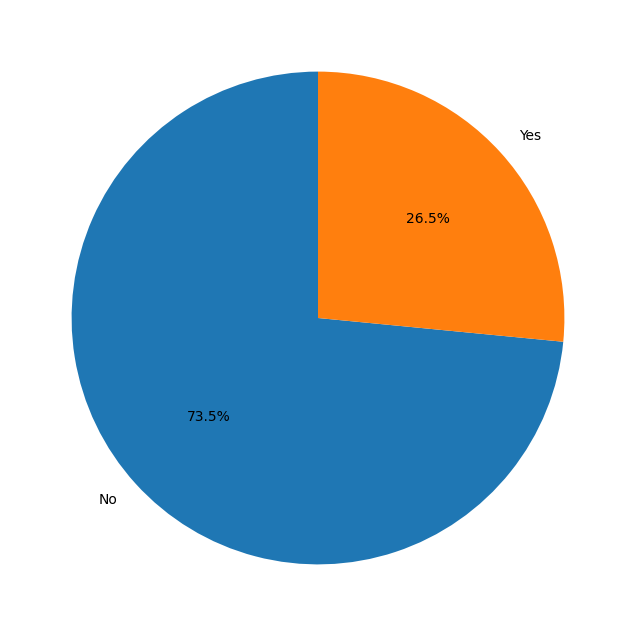

In [31]:
# a. Build a pie-chart to show the distribution of customers would be churning out

plt.figure(figsize = (8,8))
plt.pie(df['Churn'].value_counts(), labels = df['Churn'].value_counts().index, autopct = '%1.1f%%', startangle = 90)
plt.show()

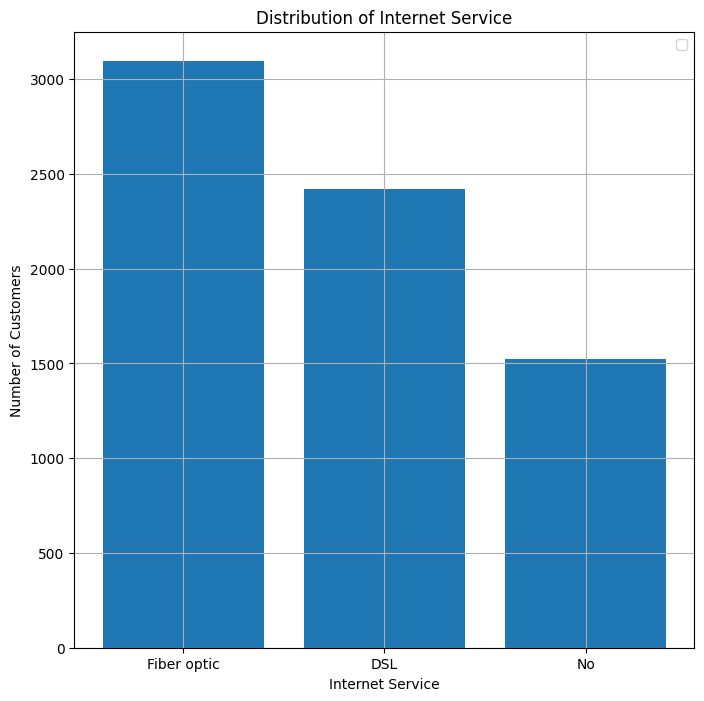

In [33]:
# b. Build a bar-plot to show the distribution of ‘Internet Service’

plt.figure(figsize = (8,8))
plt.bar(df['InternetService'].value_counts().index, df['InternetService'].value_counts())
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')
plt.title('Distribution of Internet Service')
plt.legend()
plt.grid(True)
plt.show()

## C) Model Building: 

In [35]:
# a. Build a sequential model using Keras, to find out if the customerwouldchurn or not, using 
# ‘tenure’ as the feature and ‘Churn’ as the dependent/target column: 

# i. The visible/input layer should have 12 nodes with ‘Relu’ as activation function.

x = df[['tenure']]

y = df['Churn'].map({'Yes' : 1 , 'No' : 0})

print("Shape of X : ", x.shape)
print("Shape of Y : ", y.shape)

Shape of X :  (7043, 1)
Shape of Y :  (7043,)


In [39]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42,stratify = y)
print("Shape of x_train : ", x_train.shape)
print("Shape of x_test : ", x_test.shape)

Shape of x_train :  (5634, 1)
Shape of x_test :  (1409, 1)


In [42]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential()

model.add(Dense(12, input_dim= 1, activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(1, activation='sigmoid'))


In [43]:
model.compile(loss = 'binary_crossentropy', optimizer = 'adam' , metrics = ['accuracy'])


In [44]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 137 (548.00 B)

 Trainable params: 137 (548.00 B)

 Non-trainable params: 0 (0.00 B)

In [46]:
history = model.fit(
    x_train,
    y_train,
    epochs=150,
    validation_split=0.2,
    verbose=1
)

Epoch 1/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7337 - loss: 0.5795 - val_accuracy: 0.7382 - val_loss: 0.5750
Epoch 2/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7337 - loss: 0.5795 - val_accuracy: 0.7382 - val_loss: 0.5749
Epoch 3/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7337 - loss: 0.5795 - val_accuracy: 0.7382 - val_loss: 0.5749
Epoch 4/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7337 - loss: 0.5795 - val_accuracy: 0.7382 - val_loss: 0.5749
Epoch 5/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7337 - loss: 0.5795 - val_accuracy: 0.7382 - val_loss: 0.5749
Epoch 6/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7337 - loss: 0.5795 - val_accuracy: 0.7382 - val_loss: 0.5749
Epoch 7/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7337 - loss: 0.5795 - val_accuracy: 0.7382 - val_loss: 0.5749
Epoch 8/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7337 - loss: 0.5795 - val_accu

In [47]:
y_pred = model.predict(x_test)

y_pred = (y_pred > 0.5).astype(int)

print(y_pred[:10])

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
[[0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]]


Confusion Matrix:
 [[1035    0]
 [ 374    0]]


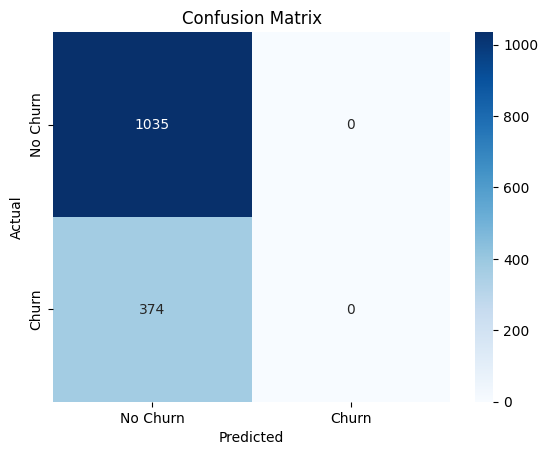

In [50]:
from sklearn.metrics import classification_report, confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',xticklabels=['No Churn', 'Churn'],yticklabels=['No Churn', 'Churn']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


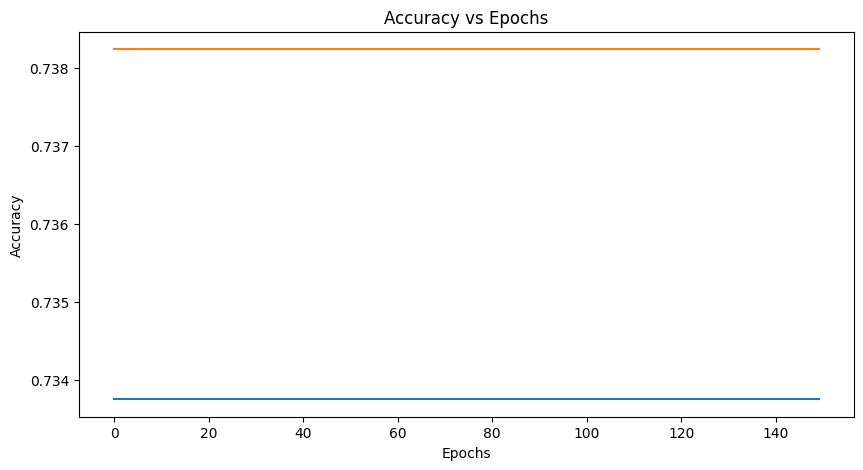

In [52]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Epochs')
plt.show()

## b. Build the 2nd model using same target and feature variables: 


In [56]:
# i. Add a drop-out layer after the input layer with drop-out value of 0.3 
# ii. Add a drop-out layer after the hidden layer with drop-out value of 0.2 
# iii. Predict the values on the test set and build a confusion matrix 
# iv. Plot the ‘Accuracy vs Epochs’ graph 

In [57]:
from tensorflow.keras.layers import Dropout
model2 = Sequential()

model2.add(Dense(12, input_dim=1, activation='relu'))
model2.add(Dropout(0.3))
model2.add(Dense(8, activation='relu'))
model2.add(Dropout(0.2))
model2.add(Dense(1, activation='sigmoid'))

In [58]:
model2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [60]:
history2 = model2.fit(
    x_train,
    y_train,
    epochs=150,
    validation_split=0.2,
    verbose=1
)

Epoch 1/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.4526 - loss: 6.4482 - val_accuracy: 0.7382 - val_loss: 0.8984
Epoch 2/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6432 - loss: 1.5391 - val_accuracy: 0.7382 - val_loss: 0.5636
Epoch 3/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6683 - loss: 1.0495 - val_accuracy: 0.7382 - val_loss: 0.5175
Epoch 4/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6843 - loss: 0.8061 - val_accuracy: 0.7382 - val_loss: 0.5227
Epoch 5/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6943 - loss: 0.7281 - val_accuracy: 0.7382 - val_loss: 0.5371
Epoch 6/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7018 - loss: 0.7175 - val_accuracy: 0.7382 - val_loss: 0.5396
Epoch 7/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7045 - loss: 0.6651 - val_accuracy: 0.7382 - val_loss: 0.5489
Epoch 8/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7080 - loss: 0.6561 - val_accu

In [61]:
y_pred2 = model2.predict(x_test)

y_pred2 = (y_pred2 >= 0.5).astype(int)

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step


[[1035    0]
 [ 374    0]]


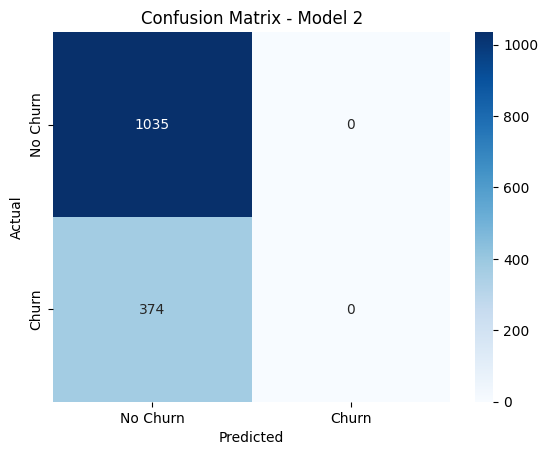

In [62]:
cm2 = confusion_matrix(y_test, y_pred2)

print(cm2)

sns.heatmap(
    cm2,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Model 2')
plt.show()

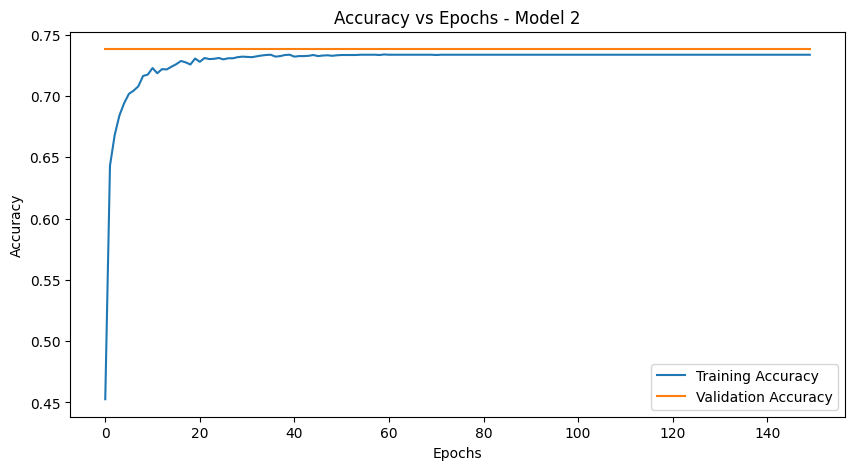

In [63]:
plt.figure(figsize=(10, 5))

plt.plot(history2.history['accuracy'], label='Training Accuracy')
plt.plot(history2.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Epochs - Model 2')

plt.legend()
plt.show()

## c. Build the 3rd model using ‘Tenure’, ’Monthly Charges’ & ‘Total Charges’ as the features and 
‘Churn’ as the dependent/target column: 

In [64]:
# i. The visible/input layer should have 12 nodes with ‘Relu’ as activation function. 
# ii. This model would have 1 hidden layer with 8 nodes and ‘Relu’ as activation function
# iii. Use ‘Adam’ as the optimization algorithm  
# iv. Fit the model on the train set, with number of epochs to be 150 
# v. Predict the values on the test set and build a confusion matrix  
# vi.Plot the ‘Accuracy vs Epochs’ graph 

In [66]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')


In [68]:

# Fill blank TotalCharges with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [69]:
X3 = df[['tenure', 'MonthlyCharges', 'TotalCharges']]

In [73]:
y3 = df['Churn'].map({'No': 0, 'Yes': 1})

print(X3.head())
print(y3.head())

print(X3.shape)
print(y3.shape)

   tenure  MonthlyCharges  TotalCharges
0       1           29.85         29.85
1      34           56.95       1889.50
2       2           53.85        108.15
3      45           42.30       1840.75
4       2           70.70        151.65
0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64
(7043, 3)
(7043,)


In [74]:
x3_train, x3_test, y3_train, y3_test = train_test_split(X3, y3, test_size=0.2, random_state=42, stratify=y3)

print(x3_train.shape)
print(x3_test.shape)

(5634, 3)
(1409, 3)


In [77]:
from sklearn.preprocessing import StandardScaler

scaller = StandardScaler()

x3_train_scaled = scaller.fit_transform(x3_train)
x3_test_scaled = scaller.transform(x3_test)

In [83]:
from tensorflow.keras.layers import Input

model3 = Sequential()

model3.add(Input(shape=(3,)))
model3.add(Dense(12,activation='relu'))
model3.add(Dense(8, activation='relu'))
model3.add(Dense(1, activation='sigmoid'))


In [84]:
model3.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [85]:
model3.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 12)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 161 (644.00 B)

 Trainable params: 161 (644.00 B)

 Non-trainable params: 0 (0.00 B)

In [87]:
history3 = model3.fit(
    x3_train,
    y3_train,
    epochs=150,
    validation_split=0.2,
    verbose=1
)

Epoch 1/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.5494 - loss: 2.3219 - val_accuracy: 0.5244 - val_loss: 1.2402
Epoch 2/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6159 - loss: 1.2178 - val_accuracy: 0.7320 - val_loss: 1.1483
Epoch 3/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6852 - loss: 0.9668 - val_accuracy: 0.7338 - val_loss: 0.6923
Epoch 4/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7049 - loss: 1.0029 - val_accuracy: 0.7267 - val_loss: 0.6661
Epoch 5/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7067 - loss: 0.7538 - val_accuracy: 0.7427 - val_loss: 0.7056
Epoch 6/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7027 - loss: 0.7824 - val_accuracy: 0.7489 - val_loss: 0.8954
Epoch 7/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7096 - loss: 0.8874 - val_accuracy: 0.5084 - val_loss: 0.9661
Epoch 8/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7171 - loss: 0.6399 - val_accu

In [88]:
y_pred3 = model3.predict(x3_test)

y_pred3 = (y_pred3 >= 0.5).astype(int)

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


[[918 117]
 [197 177]]


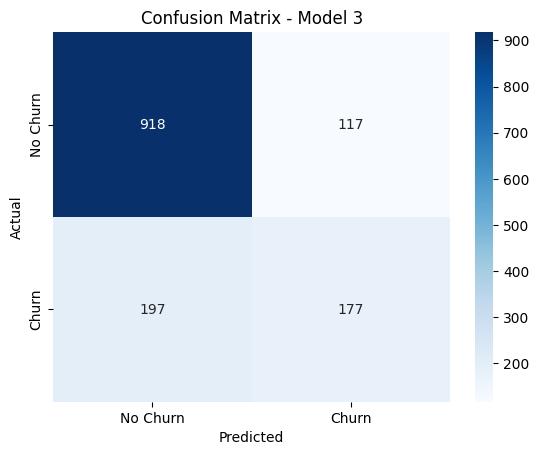

In [89]:
cm3 = confusion_matrix(y3_test, y_pred3)

print(cm3)

sns.heatmap(
    cm3,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Model 3')
plt.show()

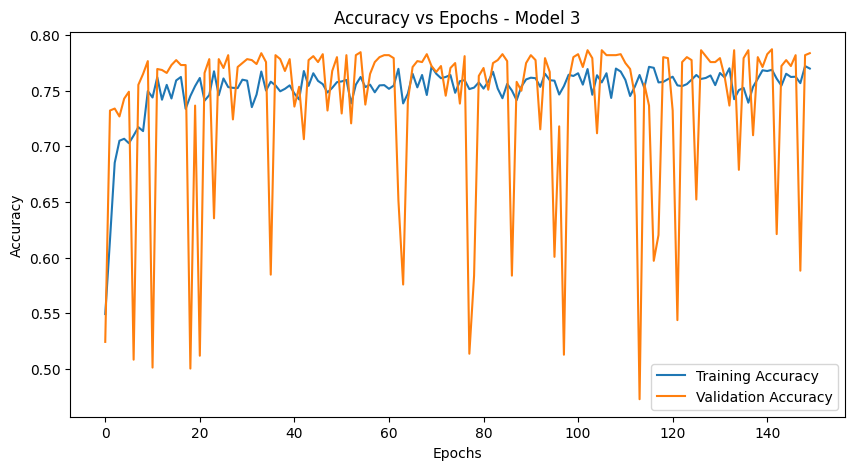

In [90]:
plt.figure(figsize=(10, 5))

plt.plot(history3.history['accuracy'], label='Training Accuracy')
plt.plot(history3.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Epochs - Model 3')

plt.legend()
plt.show()